# Testing out model training before script

In [ ]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import datetime

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import DictVectorizer

import training

elections = training.dedupe_elections(training.load_view())
elections = training.preprocess_filter_elections(elections)

elections = training.calc_finance_cols(elections)
elections = training.calc_election_cols(elections)

data_reg = training.regression_dataset(elections)
data_clf = training.classification_dataset(elections)

Loaded data has 22196 rows and 49 columns
Dropped duplicates by election id. Have 22196 rows
Dropping 9 rows where elections are not for single labor organization.
Dropping 93 rows where total votes is not >0.
Dropping 2997 rows where ttl_disbursements is null (no finance info)
Dropping 44 rows where unit_size is null (cannot calculate turnout)
Dropping 0 rows where members is null (cannot calculate per member spending)
Dropping 610 rows where total disbursements or members is zero.


## Linear Regression

In [2]:
df_full_train, df_test = train_test_split(data_reg, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

print(f"Test: {len(df_test)} rows, Train: {len(df_train)} rows, Validation: {len(df_val)}")

y_train =  df_train['net_margin'].values
y_val = df_val['net_margin'].values
y_test = df_test['net_margin'].values

X_train, X_val, X_test = df_train[training.FEATURES], df_val[training.FEATURES], df_test[training.FEATURES]

# Just to be sure
del df_train['net_margin']
del df_val['net_margin']
del df_test['net_margin']


Test: 3593 rows, Train: 10776 rows, Validation: 3592


In [3]:
# Removing nulls

# Checking missingness on feature columns
df_train.isna().mean().sort_values(ascending=False).head(30)

case_type            0.0
state                0.0
unit_size            0.0
turnout              0.0
days_to_election     0.0
log_members          0.0
log_rep_per_mem      0.0
log_admin_per_mem    0.0
finance_aff_abbr     0.0
dtype: float64

In [20]:
# One hot encoding
dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(df_train[training.FEATURES].to_dict(orient='records'))
X_val = dv.transform(df_val[training.FEATURES].to_dict(orient='records'))

print(X_train.shape)
print(X_val.shape)

(10776, 137)
(3592, 137)


# Terrible results when one hot encoding. Try testing removing each category?

In [56]:
CUSTOM_FEATURES = [
    # filing / election
    "case_type",
    "state",
    "unit_size",
    "turnout",
    "days_to_election",
    # union finance
    "log_members",
    "log_rep_per_mem",
    "log_admin_per_mem",
    "finance_aff_abbr",
]

In [57]:
dv2 = DictVectorizer(sparse=False)

print(CUSTOM_FEATURES)

X_train = dv2.fit_transform(df_train[CUSTOM_FEATURES].to_dict(orient='records'))
X_val = dv2.transform(df_val[CUSTOM_FEATURES].to_dict(orient='records'))

print(X_train.shape)
print(X_val.shape)

['case_type', 'state', 'unit_size', 'turnout', 'days_to_election', 'log_members', 'log_rep_per_mem', 'log_admin_per_mem', 'finance_aff_abbr']
(10776, 137)
(3592, 137)


In [58]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

lr = LinearRegression()

model = lr.fit(X_train, y_train)

pred = model.predict(X_val)

rmse = np.sqrt(mean_squared_error(y_val, pred))
print(f"Linear  RMSE: {rmse:.4f}  R^2: {r2_score(y_val, pred):.4f}")

Linear  RMSE: 0.5200  R^2: 0.0969


In [ ]:
# Regularization required? Check size of coefficients

model.coef_

array([ 1.45131186e-01, -1.45131186e-01, -4.58613576e-04, -1.61848144e-02,
        1.38937704e-02,  1.82642297e-02, -4.51353153e-01, -3.96593159e-04])

## Logistic Regression

In [68]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

df_full_train, df_test = train_test_split(data_clf, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

print(f"Test: {len(df_test)} rows, Train: {len(df_train)} rows, Validation: {len(df_val)}")

y_train =  df_train['success'].values
y_val = df_val['success'].values
y_test = df_test['success'].values

X_train, X_val, X_test = df_train[training.FEATURES], df_val[training.FEATURES], df_test[training.FEATURES]

# Just to be sure
del df_train['success']
del df_val['success']
del df_test['success']

Test: 3593 rows, Train: 10776 rows, Validation: 3592


In [72]:

CUSTOM_FEATURES = [
    # filing / election
    "case_type",
    "state",
    "unit_size",
    "turnout",
    "days_to_election",
    # union finance
    "log_members",
    "log_rep_per_mem",
    "log_admin_per_mem",
    # "finance_aff_abbr",
]

dv2 = DictVectorizer(sparse=False)

print(CUSTOM_FEATURES)

X_train = dv2.fit_transform(df_train[CUSTOM_FEATURES].to_dict(orient='records'))
X_val = dv2.transform(df_val[CUSTOM_FEATURES].to_dict(orient='records'))

print(X_train.shape)
print(X_val.shape)

['case_type', 'state', 'unit_size', 'turnout', 'days_to_election', 'log_members', 'log_rep_per_mem', 'log_admin_per_mem']
(10776, 62)
(3592, 62)


In [73]:
logistic_model = LogisticRegression(solver='lbfgs', max_iter=200)

logistic_model.fit(X_train, y_train)

/home/peishi/machine-learning-zoomcamp/union-elections-modeling/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",200
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in

In [ ]:
y_pred = logistic_model.predict_proba(X_val)[:, 1]

for thres in np.arange(0.1, 0.9, 0.1):
    election_outcome = (y_pred > thres)
    accuracy = (y_val == election_outcome).mean()
    auc = roc_auc_score(y_val, election_outcome)
    print(f"For threshold {thres}, accuracy: {accuracy:.2f}, ROC AUC: {auc:.2f}")

For threshold 0.1, accuracy: 0.69, ROC AUC: 0.50
For threshold 0.2, accuracy: 0.70, ROC AUC: 0.50
For threshold 0.30000000000000004, accuracy: 0.70, ROC AUC: 0.50
For threshold 0.4, accuracy: 0.69, ROC AUC: 0.50
For threshold 0.5, accuracy: 0.69, ROC AUC: 0.52
For threshold 0.6, accuracy: 0.68, ROC AUC: 0.56
For threshold 0.7000000000000001, accuracy: 0.57, ROC AUC: 0.60
For threshold 0.8, accuracy: 0.36, ROC AUC: 0.53


## Random Forest

In [80]:
from sklearn.ensemble import RandomForestClassifier

df_full_train, df_test = train_test_split(data_clf, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

print(f"Test: {len(df_test)} rows, Train: {len(df_train)} rows, Validation: {len(df_val)}")

y_train =  df_train['success'].values
y_val = df_val['success'].values
y_test = df_test['success'].values

X_train, X_val, X_test = df_train[training.FEATURES], df_val[training.FEATURES], df_test[training.FEATURES]

# Just to be sure
del df_train['success']
del df_val['success']
del df_test['success']

Test: 3593 rows, Train: 10776 rows, Validation: 3592


In [81]:
CUSTOM_FEATURES = [
    # filing / election
    "case_type",
    "state",
    "unit_size",
    "turnout",
    "days_to_election",
    # union finance
    "log_members",
    "log_rep_per_mem",
    "log_admin_per_mem",
    "finance_aff_abbr",
]

dv2 = DictVectorizer(sparse=False)

print(CUSTOM_FEATURES)

X_train = dv2.fit_transform(df_train[CUSTOM_FEATURES].to_dict(orient='records'))
X_val = dv2.transform(df_val[CUSTOM_FEATURES].to_dict(orient='records'))

print(X_train.shape)
print(X_val.shape)

['case_type', 'state', 'unit_size', 'turnout', 'days_to_election', 'log_members', 'log_rep_per_mem', 'log_admin_per_mem', 'finance_aff_abbr']
(10776, 137)
(3592, 137)


### Parameter tuning: number of estimators, minimum samples in each leaf, maximum tree depth

In [92]:
scores = []

for d in [10, 15, 20, 25]:
    for n in range(20, 401, 20):
        rf = RandomForestClassifier(n_estimators=n, max_depth=d, random_state=1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((d, n, auc))

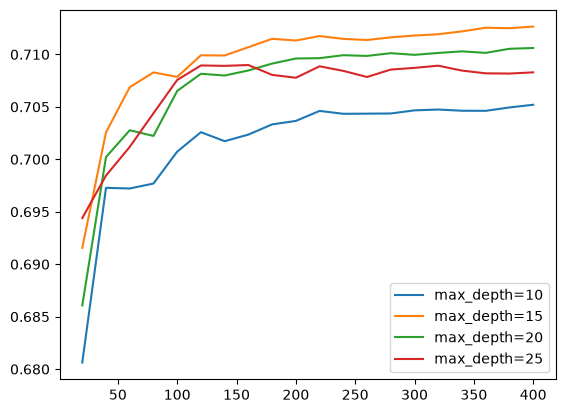

In [94]:
columns = ['max_depth', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

for d in [10, 15, 20, 25]:
    df_subset = df_scores[df_scores.max_depth == d]

    plt.plot(df_subset.n_estimators, df_subset.auc,
             label='max_depth=%d' % d)
    plt.legend()

In [95]:
max_depth = 15

scores = []

for s in [1, 3, 5, 10, 50]:
    for n in range(20, 500, 20):
        rf = RandomForestClassifier(n_estimators=n,
                                    max_depth=max_depth,
                                    min_samples_leaf=s,
                                    random_state=1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((s, n, auc))

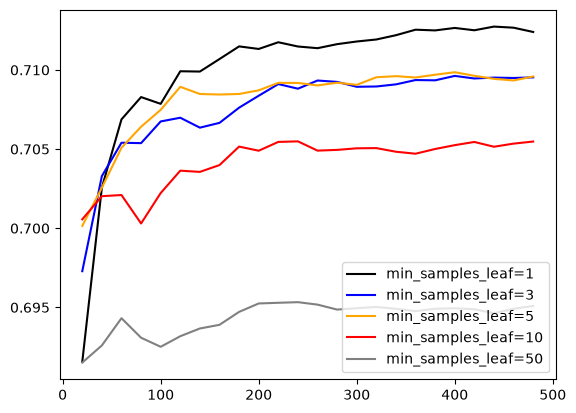

In [96]:
columns = ['min_samples_leaf', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

colors = ['black', 'blue', 'orange', 'red', 'grey']
values = [1, 3, 5, 10, 50]

for s, col in zip(values, colors):
    df_subset = df_scores[df_scores.min_samples_leaf == s]

    plt.plot(df_subset.n_estimators, df_subset.auc,
             color=col,
             label='min_samples_leaf=%d' % s)

plt.legend()

In [ ]:
# Best model 

max_depth = 15
min_samples_leaf = 1
n = 450

rf = RandomForestClassifier(
    n_estimators=n,
    max_depth=max_depth,
    min_samples_leaf=min_samples_leaf,
    random_state=1
)

rf.fit(X_train, y_train)

In [99]:
y_pred = rf.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred)

print(f"with max_depth: {max_depth}, min_samples_leaf: {min_samples_leaf}, and n_estimators: {n}")
print(f"ROC AUC is {auc}")

with max_depth: 15, min_samples_leaf: 1, and n_estimators: 450
ROC AUC is 0.7128505498807338


In [100]:
importances = pd.Series(rf.feature_importances_, index=dv2.get_feature_names_out())
print(importances.sort_values(ascending=False).head(20))

unit_size                0.141284
turnout                  0.125737
days_to_election         0.113784
log_members              0.105152
log_rep_per_mem          0.090046
log_admin_per_mem        0.087708
finance_aff_abbr=IBT     0.019333
state=MN                 0.014190
case_type=RM             0.012905
finance_aff_abbr=WU      0.012562
case_type=RC             0.012461
finance_aff_abbr=UFCW    0.012155
state=OH                 0.010442
state=CA                 0.008662
state=NY                 0.007319
finance_aff_abbr=SEIU    0.007276
finance_aff_abbr=IAM     0.007147
state=IA                 0.006799
finance_aff_abbr=AFT     0.006762
finance_aff_abbr=IBEW    0.006608
dtype: float64
